# 02 Data cleaning – Rama & Uyazi
**Goal:** turn the raw 2009 H1N1 Flu Survey data into a clean, model-ready table with steps that can be re-used on the test set.

This notebook combines both of our cleaning notebooks. All logic lives in `src/cleaning.py`; the notebook shows the evidence for each decision and calls the functions.
Parts marked **(Uyazi)** come from Uyazi's notebook, parts marked **(Rama)** from Rama's. See `reports/cleaning_changes.md` for what changed and why.

**Rules:** (1) never change the raw data, (2) check before you fill, (3) anything *learned* from data (common job codes, most frequent values) is learned from the **training** set only and then applied to the test set.

Tickets: 1.1 (quality), 1.2 (missing values), 1.7 (high-cardinality columns), 1.9 (cleaning code).

In [4]:
import sys
sys.path.append("..")
from pathlib import Path
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from src.cleaning import (TARGETS, tidy_text, check_ranges, validate, rare_levels,
                          clean, learn_modes, fill_numeric)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60)

train_X = pd.read_csv("../data/training_set_features.csv")
train_y = pd.read_csv("../data/training_set_labels.csv")
test_X = pd.read_csv("../data/test_set_features.csv")

raw = train_X.merge(train_y, on="respondent_id", validate="one_to_one")   # raw training data
print("train:", raw.shape, "| test:", test_X.shape)

train: (26707, 38) | test: (26708, 36)


## 1. Quality checks (tickets 1.1)

In [5]:
print("Respondent ids unique:", raw["respondent_id"].is_unique)
print("Duplicate answer rows :", raw.drop(columns="respondent_id").duplicated().sum())
print("Missing in the targets :", raw[TARGETS].isnull().sum().to_dict())
print("Values outside the expected range:")
check_ranges(raw)

Respondent ids unique: True
Duplicate answer rows : 0
Missing in the targets : {'h1n1_vaccine': 0, 'seasonal_vaccine': 0}
Values outside the expected range:


,column,bad values


## 2. Tidy text (Uyazi)
`census_msa` contains a double space (`"MSA, Not Principle  City"`). `tidy_text` strips and collapses whitespace so categories are never split by invisible differences.

In [6]:
print("before:", sorted(raw["census_msa"].dropna().unique()))
print("after :", sorted(tidy_text(raw)["census_msa"].dropna().unique()))

before: ['MSA, Not Principle  City', 'MSA, Principle City', 'Non-MSA']
after : ['MSA, Not Principle City', 'MSA, Principle City', 'Non-MSA']


## 3. Missing values (ticket 1.2)

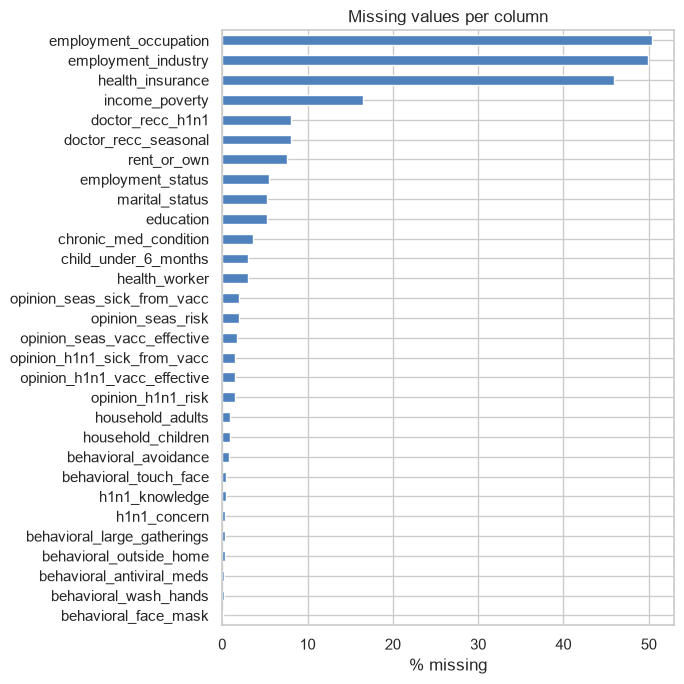

In [7]:
missing = raw.isnull().mean().mul(100).sort_values(ascending=False)
missing = missing[missing > 0]
ax = missing.sort_values().plot.barh(figsize=(7, 7), color="#4f81bd")
ax.set_xlabel("% missing"); ax.set_title("Missing values per column")
plt.tight_layout(); plt.show()

### Is *missing* related to vaccination? (Rama)
If vaccination rates differ between people who skipped a question and people who answered it, the gap itself carries information and must not be erased.

In [8]:
rows = []
for col in missing.index:
    m = raw[col].isnull()
    rows.append({"column": col, "% missing": round(m.mean() * 100, 1),
                 "h1n1 if missing": round(raw.loc[m, "h1n1_vaccine"].mean(), 3),
                 "h1n1 if answered": round(raw.loc[~m, "h1n1_vaccine"].mean(), 3),
                 "seasonal if missing": round(raw.loc[m, "seasonal_vaccine"].mean(), 3),
                 "seasonal if answered": round(raw.loc[~m, "seasonal_vaccine"].mean(), 3)})
pd.DataFrame(rows)

,column,% missing,h1n1 if missing,h1n1 if answered,seasonal if missing,seasonal if answered
0,employment_occupation,50.4,0.209,0.216,0.508,0.422
1,employment_industry,49.9,0.208,0.217,0.508,0.423
2,health_insurance,46.0,0.113,0.297,0.424,0.501
3,income_poverty,16.6,0.189,0.217,0.448,0.469
4,doctor_recc_h1n1,8.1,0.086,0.224,0.352,0.476
5,doctor_recc_seasonal,8.1,0.086,0.224,0.352,0.476
6,rent_or_own,7.6,0.194,0.214,0.419,0.469
7,employment_status,5.5,0.185,0.214,0.388,0.470
8,marital_status,5.3,0.182,0.214,0.389,0.470
9,education,5.3,0.186,0.214,0.385,0.470


**Decisions**
| Column(s) | Finding | Decision |
|---|---|---|
| Columns with > 5 % missing **(Uyazi's rule)** | Skipped questions can be informative | Add a `<col>_missing` flag *before* filling |
| `health_insurance` (46 %) | H1N1 uptake 11 % if missing vs 30 % if answered | Flag; fill only for the model, the flag keeps the signal |
| `household_*` (1 %) **(Rama)** | Seasonal uptake about 26 % if missing vs 47 % | Flag as well, although they are below 5 % |
| `employment_industry/occupation` | Missing mostly because the person does not work | `Not employed` (see section 4), no extra flag needed |
| Remaining text gaps | Small | Category `Missing` |
| Remaining numeric gaps | 0.1–8 % | Most frequent value from the **training** set (flags keep the information); in Sprint 2 move this into a Pipeline |

## 4. Employment columns

In [9]:
no_industry = raw["employment_industry"].isnull()
print(raw.loc[no_industry, "employment_status"].value_counts(dropna=False))

employment_status
Not in Labor Force    10231
NaN                    1463
Unemployed             1453
Employed                183
Name: count, dtype: int64


10,231 are *Not in Labor Force* and 1,453 *Unemployed* → `Not employed` (Uyazi's label). 1,463 have no employment status at all → `Missing`. Only 183 employed people are really missing an industry.

## 5. High-cardinality columns (ticket 1.7) (Rama)

In [10]:
def level_table(col):
    s = raw[col].fillna("(missing)")
    t = raw.groupby(s)[TARGETS].mean().round(3)
    t["n"] = s.value_counts()
    t["% of people"] = (t["n"] / len(raw) * 100).round(1)
    return t.sort_values("n", ascending=False)

level_table("employment_industry")

,h1n1_vaccine,seasonal_vaccine,n,% of people
employment_industry,,,,
(missing),0.208,0.508,13330,49.9
fcxhlnwr,0.398,0.638,2468,9.2
wxleyezf,0.246,0.454,1804,6.8
ldnlellj,0.172,0.381,1231,4.6
pxcmvdjn,0.138,0.353,1037,3.9
atmlpfrs,0.134,0.375,926,3.5
arjwrbjb,0.239,0.460,871,3.3
xicduogh,0.123,0.241,851,3.2
mfikgejo,0.163,0.436,614,2.3


In [11]:
level_table("employment_occupation")

,h1n1_vaccine,seasonal_vaccine,n,% of people
employment_occupation,,,,
(missing),0.209,0.508,13470,50.4
xtkaffoo,0.204,0.418,1778,6.7
mxkfnird,0.177,0.436,1509,5.7
emcorrxb,0.236,0.457,1270,4.8
cmhcxjea,0.471,0.688,1247,4.7
xgwztkwe,0.133,0.336,1082,4.1
hfxkjkmi,0.161,0.428,766,2.9
qxajmpny,0.108,0.201,548,2.1
xqwwgdyp,0.142,0.330,485,1.8


In [12]:
level_table("hhs_geo_region")

,h1n1_vaccine,seasonal_vaccine,n,% of people
hhs_geo_region,,,,
lzgpxyit,0.180,0.453,4297,16.1
fpwskwrf,0.202,0.474,3265,12.2
qufhixun,0.222,0.468,3102,11.6
oxchjgsf,0.231,0.468,2859,10.7
kbazzjca,0.198,0.481,2858,10.7
bhuqouqj,0.259,0.496,2846,10.7
mlyzmhmf,0.230,0.449,2243,8.4
lrircsnp,0.210,0.413,2078,7.8
atmpeygn,0.217,0.493,2033,7.6


In [13]:
a = raw["employment_industry"] == "haxffmxo"
b = raw["employment_occupation"] == "dcjcmpih"
print("industry haxffmxo:", a.sum(), "| occupation dcjcmpih:", b.sum(), "| same people:", (a & b).sum())

industry haxffmxo: 148 | occupation dcjcmpih: 148 | same people: 148


**Decisions**
- Grouping by frequency alone is a bad rule: `haxffmxo` / `dcjcmpih` are small (148 people, the **same** people) but have a 62 % H1N1 uptake.
- Only codes with fewer than 100 people become `Other`. The list is learned from the **training** set (`rare_levels`) and re-used for the test set.
- `hhs_geo_region` stays as it is (10 regions, 18–26 % H1N1 uptake).

## 6. Apply the cleaning to train **and** test

In [14]:
keep = rare_levels(tidy_text(raw))              # learned from TRAIN only
train_c = clean(raw, keep)                      # text, flags, job codes, ordered columns
modes = learn_modes(train_c)                    # most frequent values from TRAIN only
train_clean = fill_numeric(train_c, modes)
test_clean = fill_numeric(clean(test_X, keep), modes)

print("train:", train_clean.shape, "| test:", test_clean.shape)
print("job codes kept:", {c: len(v) for c, v in keep.items()})

train: (26707, 52) | test: (26708, 50)
job codes kept: {'employment_industry': 19, 'employment_occupation': 22}


## 7. Validation (Uyazi's assertions, now reusable functions)

In [15]:
validate(train_clean, raw=raw)      # no gaps, ids unique, ranges ok, rows and targets unchanged
validate(test_clean)                # same rules for the test set
print("All checks passed.")
print("Same feature columns in train and test:",
      list(train_clean.drop(columns=TARGETS).columns) == list(test_clean.columns))

All checks passed.
Same feature columns in train and test: True


In [16]:
# Cleaning must not change the vaccination rates
pd.DataFrame({"raw %": raw[TARGETS].mean().mul(100).round(1),
              "clean %": train_clean[TARGETS].mean().mul(100).round(1)})

,raw %,clean %
h1n1_vaccine,21.2,21.2
seasonal_vaccine,46.6,46.6


In [17]:
bins = pd.cut(train_clean["n_missing_answers"], [-1, 0, 1, 2, 4, 30])
train_clean.groupby(bins, observed=True)[TARGETS].agg(["mean", "count"]).round(3)

h1n1_vaccine        seasonal_vaccine       
                          mean  count             mean  count
n_missing_answers                                            
(-1, 0]                  0.302  11794            0.502  11794
(0, 1]                   0.148   9563            0.453   9563
(1, 2]                   0.164   1845            0.461   1845
(2, 4]                   0.071   2138            0.381   2138
(4, 30]                  0.176   1367            0.375   1367

## 8. Save

In [18]:
out = Path("../data/processed")
out.mkdir(parents=True, exist_ok=True)
train_clean.set_index("respondent_id").to_csv(out / "train_clean.csv")     # id as index (Uyazi)
test_clean.set_index("respondent_id").to_csv(out / "test_clean.csv")
print("saved to", out.resolve())

saved to /Users/rama/data-circle/projects/flu-predictors/data/processed


CSV files are ignored by Git, so teammates re-create them by running this notebook.

In [19]:
new_cols = [c for c in train_clean.columns if c not in raw.columns]
pd.DataFrame({"new column": new_cols, "dtype": [str(train_clean[c].dtype) for c in new_cols]})

,new column,dtype
0,n_missing_answers,int64
1,health_insurance_missing,int8
2,doctor_recc_h1n1_missing,int8
3,doctor_recc_seasonal_missing,int8
4,income_poverty_missing,int8
5,employment_status_missing,int8
6,education_missing,int8
7,marital_status_missing,int8
8,rent_or_own_missing,int8
9,household_adults_missing,int8


## Decision log (copy to `workflow.md`)
| Decision | Reason | From |
|---|---|---|
| Strip / collapse whitespace in text | `census_msa` had a double space | Uyazi |
| Flag every column with > 5 % missing (plus `household_*`) before filling | Missingness is related to vaccination | Uyazi + Rama |
| `Not employed` / `Missing` labels | Clear names, one convention | Uyazi |
| Job codes < 100 people → `Other`, larger rare ones kept | Rare codes can be very different (62 % uptake) | Rama |
| Ordered columns `age_group_ord`, `education_ord`, `income_ord` | Keeps the order for linear models | Rama |
| Numeric gaps filled with training-set modes | Small gaps; flags keep the signal | Uyazi (made reusable by Rama) |
| `validate()` after cleaning | Catches silent errors early | Uyazi |
| Fill values learned from train only, then applied to test | No leakage; same rules for new data | Rama |
| Sprint 2: move the mode fill into a Pipeline | Re-learned inside every CV fold | both |